<a href="https://colab.research.google.com/github/monroeu/MG628/blob/main/MG628_Week5_Descriptive_Analytics_Practice_Colab_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MG628 · Week 5 Assignment
## Descriptive Analytics and Statistics
**Student workbook | Google Colab / Jupyter Notebook**

**Course:** Data Analysis for Managerial Decision-Making  
**Total:** 100 points per assigned track  
**Submission:** One completed `.ipynb` notebook.

> **Student work policy:** This notebook provides the required analytical code, detailed explanations, and blank response areas. It deliberately does **not** write the interpretation or executive summary for you. Run the cells, examine your results, and compose your own responses.

**Choose only the question set for your major:** Healthcare Administration **or** Business/Public Administration. Both are reproduced because they appear in the attached assignment. You do not need to complete both sets.

**Student name:** ____________________  
**Major:** ____________________  
**Date:** ____________________

## How to use this workbook in Google Colab
1. Open this notebook in [Google Colab](https://colab.research.google.com/).
2. Run the **Shared setup** code cell once. **Do not upload a dataset:** each track loads its assigned CSV directly from the course GitHub repository.
3. Find **TRACK A — Healthcare Administration** or **TRACK B — Business/Public Administration** and run the code cells for your major **in order**.
4. Read the Markdown guidance and detailed Python comments alongside each step.
5. Replace each **YOUR RESPONSE** placeholder with your own analysis. The notebook does not provide written answers.
6. Preserve the charts and outputs, then download your completed `.ipynb` and submit as directed on Blackboard.

**Course data repository:** [monroeu/MG628/week05/data](https://github.com/monroeu/MG628/tree/main/week05/data).

**About screenshots:** The assignment PDF requests screenshots for specific results and charts. Retain the code outputs in your submitted notebook and provide screenshots if Blackboard separately requires them.

**Dataset clarification:** The healthcare track uses the full 50-record healthcare assignment dataset, not the inconsistent seven-row Excel preview in the PDF. The healthcare cost histogram uses `Average_Cost_per_Patient`, corresponding to the PDF's generic "Unit Price" label.

## Shared setup — Python libraries and remote GitHub datasets
**Purpose:** Prepare the Python environment. Data is hosted publicly in the MG628 GitHub repository, so there is **no CSV upload step** for students.

- `pandas` reads CSV files over HTTPS and supports DataFrame analysis.
- `numpy` supports numerical calculations.
- `matplotlib.pyplot` creates visualizations.
- `display` presents tables in Colab.

**Important:** Run the setup cell, then navigate to the track for your major. Each track has its own independent GitHub loading cell.

In [1]:
# Import Pandas and give it the standard short name pd.
import pandas as pd

# Import NumPy for numerical operations and statistics support.
import numpy as np

# Import Matplotlib's plotting functions under the short name plt.
import matplotlib.pyplot as plt

# Display tables neatly in Colab or Jupyter rather than as plain text.
from IPython.display import display

# Print a setup message so you can confirm the cell ran successfully.
print('Libraries imported successfully.')

Libraries imported successfully.


### Dataset access — hosted on GitHub
The files remain in the instructor's GitHub repository at [`week05/data`](https://github.com/monroeu/MG628/tree/main/week05/data).

| Major / track | GitHub source |
|---|---|
| Healthcare Administration | [`healthcare_assignment_dataset.csv`](https://github.com/monroeu/MG628/blob/main/week05/data/healthcare_assignment_dataset.csv) |
| Business / Public Administration | [`sales_assignment_dataset.csv`](https://github.com/monroeu/MG628/blob/main/week05/data/sales_assignment_dataset.csv) |

The code below builds **raw-content HTTPS links** for Pandas. Running this code displays the source addresses but **does not download datasets**; each track downloads its own file in its Question 1 loading step. An internet connection and public access to the GitHub files are required.

In [2]:
# Set the base address where GitHub serves raw CSV file contents.
# 'raw.githubusercontent.com' returns the CSV itself, not GitHub's HTML page.
GITHUB_DATA_BASE = 'https://raw.githubusercontent.com/monroeu/MG628/refs/heads/main/week05/data'

# Form the healthcare dataset URL by appending the exact filename.
healthcare_url = f'{GITHUB_DATA_BASE}/healthcare_assignment_dataset.csv'

# Form the business/public-administration dataset URL separately.
sales_url = f'{GITHUB_DATA_BASE}/sales_assignment_dataset.csv'

# Print links for troubleshooting without showing or answering any assignment questions.
print('Healthcare CSV URL:', healthcare_url)
print('Business/Public Administration CSV URL:', sales_url)

Healthcare CSV URL: https://raw.githubusercontent.com/monroeu/MG628/refs/heads/main/week05/data/healthcare_assignment_dataset.csv
Business/Public Administration CSV URL: https://raw.githubusercontent.com/monroeu/MG628/refs/heads/main/week05/data/sales_assignment_dataset.csv


---
# TRACK A — Healthcare Administration Majors

Descriptive analytics summarizes historical healthcare records to help administrators understand patient volume, resource utilization, costs, and financial performance.

**Assignment dataset:** `healthcare_assignment_dataset.csv` (50 records)

| Column | Meaning |
|---|---|
| `Department` | Medical service line |
| `Facility` | Hospital or clinic location |
| `Physician_ID` | Physician identifier |
| `Patient_Admissions` | Patient volume for the record |
| `Average_Cost_per_Patient` | Average cost per admission in that record |
| `Total_Billing` | Reported billing for that record |

**Points:** Question 1 = 25; Question 2 = 25; Question 3 = 15; Question 4 = 10; Question 5 = 25.

## Healthcare · Question 1 (25 points) — Descriptive Statistic Summary

**Assigned steps:** (1) Load the CSV into Pandas. (2) Inspect its first 10 rows. (3) Select the three numerical variables: Patient Admissions, Average Cost per Patient, and Total Billing. (4) For each variable compute **count, mean, median, mode, standard deviation, minimum, and maximum**.

**Deliverable:** A descriptive-statistics summary covering all three variables.

### Step 1A — Load the dataset

In [3]:
# Read the healthcare CSV directly from GitHub over HTTPS into a Pandas DataFrame.
# pd.read_csv accepts URLs, so no Colab upload or local folder setup is needed.
try:
    df_healthcare = pd.read_csv(healthcare_url)
except Exception as error:
    # Show a practical explanation rather than an unexplained technical traceback.
    raise RuntimeError(
        'Cannot load healthcare CSV from GitHub. Confirm an internet connection, '
        'the repository is public, and the healthcare filename/path are unchanged. '
        f'URL: {healthcare_url}'
    ) from error

# Confirm the file loaded successfully by showing its rows-and-columns dimensions.
# This is a technical check, not a completed statistical interpretation.
print('Healthcare dataset loaded from GitHub. Rows and columns:', df_healthcare.shape)

Healthcare dataset loaded from GitHub. Rows and columns: (50, 6)


### Step 1B — Inspect the first 10 rows and column types

`head(10)` displays ten records. `info()` shows each column's data type and how many values are non-null. Use this to verify the data loaded as expected.

In [4]:
# Show the first ten rows so you can inspect the variable names and values.
display(df_healthcare.head(10))

,Department,Facility,Physician_ID,Patient_Admissions,Average_Cost_per_Patient,Total_Billing
0,Oncology,Downtown Campus,DR-008,12,2314.68,27776.16
1,Orthopedics,North Clinic,DR-004,18,1492.53,26865.54
2,Pediatrics,North Clinic,DR-003,25,2382.80,59570.00
3,Orthopedics,Downtown Campus,DR-003,8,1416.10,11328.80
4,Orthopedics,West Medical Center,DR-018,15,4282.04,64230.60
5,Emergency,East Wing Hospital,DR-012,22,3100.50,68211.00
6,Cardiology,North Clinic,DR-009,19,4850.25,92154.75
7,Pediatrics,Downtown Campus,DR-007,31,1876.42,58169.02
8,Emergency,West Medical Center,DR-015,28,2945.80,82502.40
9,Cardiology,East Wing Hospital,DR-011,14,5234.75,73286.50


In [5]:
# Print the number of records, column data types, and non-null values.
# Missing values can affect statistics and graphs if not investigated.
df_healthcare.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Department                50 non-null     object 
 1   Facility                  50 non-null     object 
 2   Physician_ID              50 non-null     object 
 3   Patient_Admissions        50 non-null     int64  
 4   Average_Cost_per_Patient  50 non-null     float64
 5   Total_Billing             50 non-null     float64
dtypes: float64(2), int64(1), object(3)
memory usage: 2.5+ KB


### Step 1C — Select the three required numerical columns

The assignment's instruction to 'create three columns' means prepare the three existing numerical fields for analysis; **do not invent new patient admissions, costs, or billing values.**

In [6]:
# List the three healthcare measurements required by the assignment.
healthcare_columns = ['Patient_Admissions', 'Average_Cost_per_Patient', 'Total_Billing']

# Make a separate numerical DataFrame containing only these fields.
healthcare_numeric = df_healthcare[healthcare_columns].copy()

# Display the selected columns so you can verify your selection.
display(healthcare_numeric.head(10))

,Patient_Admissions,Average_Cost_per_Patient,Total_Billing
0,12,2314.68,27776.16
1,18,1492.53,26865.54
2,25,2382.80,59570.00
3,8,1416.10,11328.80
4,15,4282.04,64230.60
5,22,3100.50,68211.00
6,19,4850.25,92154.75
7,31,1876.42,58169.02
8,28,2945.80,82502.40
9,14,5234.75,73286.50


### Step 1D — Count, mean, standard deviation, minimum, and maximum

`describe()` provides count, mean, sample standard deviation, minimum, quartiles, and maximum. Median and mode are shown in their own cells below so that each required measure is explicit.

In [7]:
# Compute common descriptive statistics for all three chosen fields.
# The default standard deviation uses the sample formula (n - 1).
healthcare_describe = healthcare_numeric.describe()

# Display the calculated statistics in a readable table.
display(healthcare_describe)

,Patient_Admissions,Average_Cost_per_Patient,Total_Billing
count,50.000000,50.000000,50.000000
mean,20.060000,3093.385400,60117.502400
std,9.324994,1221.385313,30611.846355
min,7.000000,1416.100000,11328.800000
25%,13.000000,2156.562500,31917.875000
50%,18.000000,2929.250000,59175.550000
75%,26.750000,4070.712500,81019.875000
max,45.000000,5234.900000,139038.750000


### Step 1E — Calculate the median

In [8]:
# The median is the middle observed value after ordering the records.
healthcare_medians = healthcare_numeric.median()

# Display the median for each of the three variables.
display(healthcare_medians.to_frame(name='Median'))

,Median
Patient_Admissions,18.00
Average_Cost_per_Patient,2929.25
Total_Billing,59175.55


### Step 1F — Calculate and interpret the mode

The **mode** is the value with the highest frequency (number of occurrences). Several values can be tied as modes. We display **one variable at a time** so Pandas does not pad a combined `.mode()` table with misleading `NaN` cells.

**Important:** When every nonmissing value occurs exactly once, no value is more frequent than another. We describe that situation as **no distinctive mode**, instead of printing a long list of values. When several values are tied at a frequency greater than one, we show all tied modes.

**Student task:** Review the mode and frequency for each of the three healthcare variables. Do not confuse display-padding `NaN` with missing observations in the original CSV.

In [9]:
# Convert mode results into a clear, compact summary string for one column.
def describe_modes(series):
    # Count the frequency of each nonmissing value.
    counts = series.value_counts(dropna=True)

    # An empty column has no observations from which to calculate a mode.
    if counts.empty:
        return 'No observations'

    # When every value occurs once, none stands out as most frequent.
    if counts.max() == 1:
        return 'No distinctive mode (all values occur once)'

    # Keep all tied most-frequent values and report how often each occurs.
    modes = series.mode(dropna=True)
    return ', '.join(str(value) for value in modes.tolist()) + f' (frequency: {counts.max()})'

# Loop through each numeric variable separately to avoid joining lists of different lengths.
for column in healthcare_columns:
    # Select one variable (one Pandas Series) by its exact column name.
    values = healthcare_numeric[column]

    # Count occurrences of each distinct nonmissing value.
    frequency_counts = values.value_counts(dropna=True)

    # Report missing data separately; these are actual missing values, if any.
    missing_count = values.isna().sum()

    # Print a heading to keep each variable's results separate.
    print(f"\nVariable: {column}")
    print(f"Missing observations in source column: {missing_count}")

    # Check that the variable contains at least one nonmissing observation.
    if frequency_counts.empty:
        print("Mode: Cannot determine (no nonmissing observations).")
        continue

    # Find the greatest observed frequency (number of appearances).
    highest_frequency = frequency_counts.max()

    # Calculate all tied modes using the Pandas method required for this lesson.
    tied_modes = values.mode(dropna=True)

    # Explain when there is no informative most-frequent value.
    if highest_frequency == 1:
        print("Mode: No distinctive mode; every observed value occurs once.")
        print("Highest frequency: 1")
    else:
        # Report modes separately rather than a NaN-padded multi-column table.
        print(f"Mode(s): {tied_modes.tolist()}")
        print(f"Frequency of each mode: {highest_frequency}")


Variable: Patient_Admissions
Missing observations in source column: 0
Mode(s): [12, 13, 14, 15]
Frequency of each mode: 3

Variable: Average_Cost_per_Patient
Missing observations in source column: 0
Mode: No distinctive mode; every observed value occurs once.
Highest frequency: 1

Variable: Total_Billing
Missing observations in source column: 0
Mode: No distinctive mode; every observed value occurs once.
Highest frequency: 1


### Step 1G — Assemble the seven required statistics in one table

In [10]:
# Create a summary table indexed by each required measurement.
healthcare_summary = pd.DataFrame(index=healthcare_columns)

# Count the non-missing observations in each numerical column.
healthcare_summary['Count'] = healthcare_numeric.count()

# Calculate the arithmetic average of each column.
healthcare_summary['Mean'] = healthcare_numeric.mean()

# Calculate the middle value for each column.
healthcare_summary['Median'] = healthcare_numeric.median()

# Show all tied modes and frequencies, or indicate when no distinctive mode exists.
healthcare_summary['Mode(s)'] = healthcare_numeric.apply(describe_modes)

# Calculate sample standard deviation: a measure of spread.
healthcare_summary['Std. Deviation'] = healthcare_numeric.std()

# Find the lowest value in each numerical column.
healthcare_summary['Minimum'] = healthcare_numeric.min()

# Find the highest value in each numerical column.
healthcare_summary['Maximum'] = healthcare_numeric.max()

# Display all seven measures as the requested descriptive-statistics summary.
display(healthcare_summary)

,Count,Mean,Median,Mode(s),Std. Deviation,Minimum,Maximum
Patient_Admissions,50,20.0600,18.00,"12, 13, 14, 15 (frequency: 3)",9.324994,7.0,45.00
Average_Cost_per_Patient,50,3093.3854,2929.25,No distinctive mode (all values occur once),1221.385313,1416.1,5234.90
Total_Billing,50,60117.5024,59175.55,No distinctive mode (all values occur once),30611.846355,11328.8,139038.75


**Your interpretation — Question 1 (write your own response):**

> **YOUR RESPONSE:** Explain the results for admissions, costs, and billing. What does the mean describe? What does the standard deviation tell an administrator? Replace this instruction with your own interpretation.

**Submission evidence:** Keep the statistics table visible in the executed notebook, or take a screenshot if requested.

## Healthcare · Question 2 (25 points) — Total Billing by Department

**Assigned task:** Create a bar chart of **Total Billing by Department** (for example, compare Cardiology and Pediatrics) to help identify high-resource service lines.

**Deliverable:** A clearly labeled bar chart (and screenshot if required).

In [11]:
# Group records by medical department.
# Sum Total_Billing for each department to compare aggregate billing.
healthcare_billing_by_department = (
    df_healthcare.groupby('Department')['Total_Billing']
    .sum()
    .sort_values(ascending=False)
)

# Display the numerical values underlying the chart.
display(healthcare_billing_by_department.to_frame(name='Total Billing ($)'))

,Total Billing ($)
Department,
Emergency,977719.25
Cardiology,820490.10
Pediatrics,564562.02
Orthopedics,346548.24
Oncology,296555.51


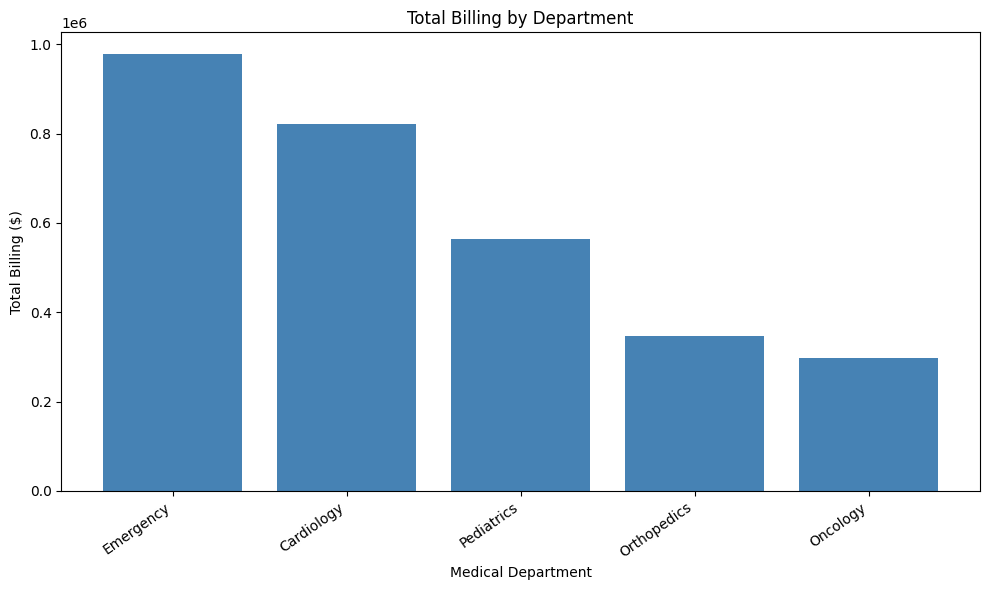

In [12]:
# Create a new figure wide enough for department labels.
plt.figure(figsize=(10, 6))

# Draw one bar per department using the previously calculated billing totals.
plt.bar(healthcare_billing_by_department.index, healthcare_billing_by_department.values, color='steelblue')

# Label the categories shown along the horizontal axis.
plt.xlabel('Medical Department')

# Label the numeric billing totals along the vertical axis.
plt.ylabel('Total Billing ($)')

# Give the chart an informative title.
plt.title('Total Billing by Department')

# Rotate category labels to keep them from overlapping.
plt.xticks(rotation=35, ha='right')

# Fit all titles and labels within the image area.
plt.tight_layout()

# Render the chart in the notebook output.
plt.show()

**Your interpretation — Question 2:**

> **YOUR RESPONSE:** Identify the department with the highest total billing and discuss what the comparison might mean. Do not assume billing equals profit or cost.

**Submission evidence:** Chart with its title and labeled axes.

## Healthcare · Question 3 (15 points) — Total Billing by Facility

**Assigned task:** Create a bar chart showing **Total Billing by Facility**, comparing locations such as Downtown Campus and North Clinic.

**Deliverable:** Clearly labeled facility comparison bar chart (and screenshot if required).

In [13]:
# Group the data by facility (the location in each record).
# Sum billing for each facility and sort from highest to lowest.
healthcare_billing_by_facility = (
    df_healthcare.groupby('Facility')['Total_Billing']
    .sum()
    .sort_values(ascending=False)
)

# Display the values used to construct the comparison.
display(healthcare_billing_by_facility.to_frame(name='Total Billing ($)'))

,Total Billing ($)
Facility,
North Clinic,824535.09
Downtown Campus,751425.13
West Medical Center,747501.90
East Wing Hospital,682413.00


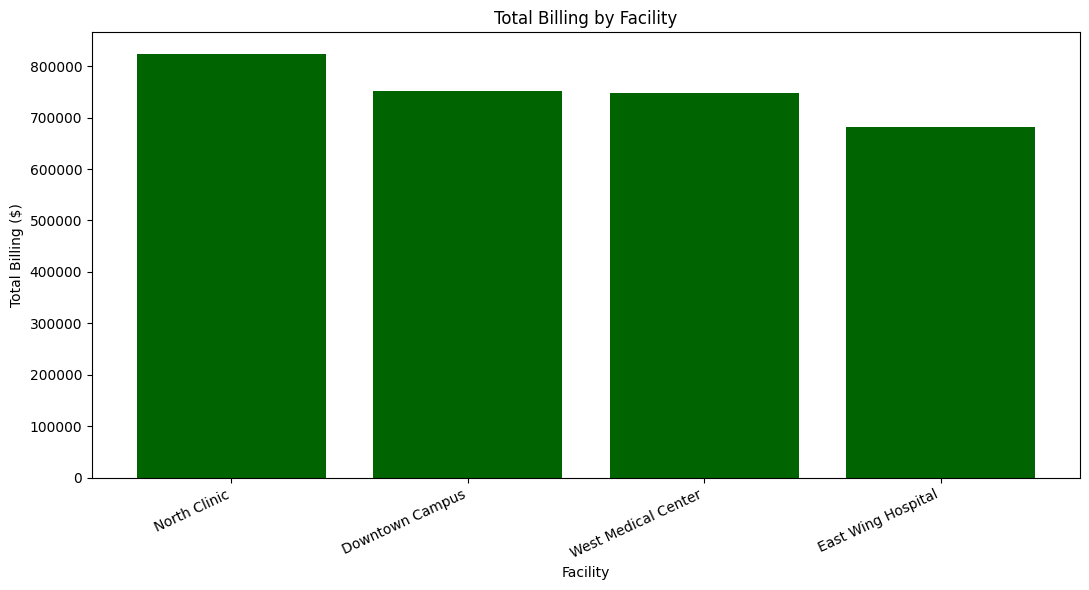

In [14]:
# Start a new chart with space for the facility names.
plt.figure(figsize=(11, 6))

# Create a bar for each facility's summed billing.
plt.bar(healthcare_billing_by_facility.index, healthcare_billing_by_facility.values, color='darkgreen')

# Label the horizontal axis with the comparison dimension.
plt.xlabel('Facility')

# Label the vertical axis with the measurement and units.
plt.ylabel('Total Billing ($)')

# Add a title explaining what the chart compares.
plt.title('Total Billing by Facility')

# Rotate longer names so they remain readable.
plt.xticks(rotation=25, ha='right')

# Automatically adjust margins to prevent cut-off labels.
plt.tight_layout()

# Show the completed chart.
plt.show()

**Your interpretation — Question 3:**

> **YOUR RESPONSE:** Compare facility billing patterns using the graph. The Question 5 prompt separately asks about **admissions**, not billing, so do not use this billing graph alone to answer the admissions question.

## Healthcare · Question 4 (10 points) — Average Cost per Patient Distribution

**Assigned task:** Produce a histogram with mean and median reference lines. The PDF labels this as *Unit Price Distribution Analysis*, but the healthcare dataset equivalent is **Average_Cost_per_Patient**.

**Deliverable:** Histogram with clearly visible mean and median lines (and screenshot if required).

In [15]:
# Calculate the mean average-cost value across all records.
healthcare_cost_mean = df_healthcare['Average_Cost_per_Patient'].mean()

# Calculate the median average-cost value across all records.
healthcare_cost_median = df_healthcare['Average_Cost_per_Patient'].median()

# Print both values so the chart's reference lines can be checked.
print('Mean average cost per patient:', healthcare_cost_mean)
print('Median average cost per patient:', healthcare_cost_median)

Mean average cost per patient: 3093.3853999999997
Median average cost per patient: 2929.25


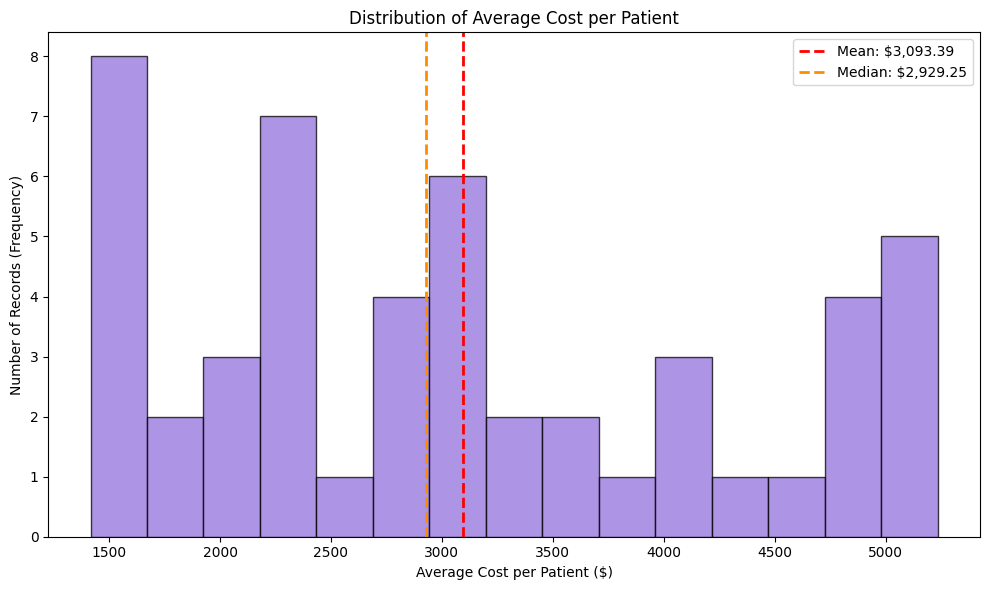

In [16]:
# Start a new figure for the frequency distribution.
plt.figure(figsize=(10, 6))

# Divide observed average costs into 15 intervals (bins).
# The bar heights show how many records fall in each interval.
plt.hist(df_healthcare['Average_Cost_per_Patient'], bins=15, color='mediumpurple', edgecolor='black', alpha=0.75)

# Draw a vertical dashed reference line at the calculated mean.
plt.axvline(healthcare_cost_mean, color='red', linestyle='--', linewidth=2, label=f'Mean: ${healthcare_cost_mean:,.2f}')

# Draw another reference line at the calculated median.
plt.axvline(healthcare_cost_median, color='darkorange', linestyle='--', linewidth=2, label=f'Median: ${healthcare_cost_median:,.2f}')

# Label both axes and the figure for interpretation.
plt.xlabel('Average Cost per Patient ($)')
plt.ylabel('Number of Records (Frequency)')
plt.title('Distribution of Average Cost per Patient')

# Display the labels for the reference lines.
plt.legend()

# Prevent chart elements from being clipped.
plt.tight_layout()

# Draw the histogram in the notebook.
plt.show()

**Your interpretation — Question 4:**

> **YOUR RESPONSE:** Describe the shape and spread of the distribution. Compare mean and median. Are average costs tightly clustered or widely varied? Support your statement with what you see.

## Healthcare · Supporting Analysis for Question 5 — Admissions by Facility

The executive-summary question asks which **facility has the highest patient admissions**. That is a different measure from Question 3's total billing. This small supporting step computes the necessary admissions totals without writing your answer.

In [17]:
# Group healthcare records by facility to assess patient volume.
# Sum admissions across all records at each location.
healthcare_admissions_by_facility = (
    df_healthcare.groupby('Facility')['Patient_Admissions']
    .sum()
    .sort_values(ascending=False)
)

# Display the admission totals; use them to develop YOUR own answer.
display(healthcare_admissions_by_facility.to_frame(name='Patient Admissions'))

,Patient Admissions
Facility,
Downtown Campus,287
North Clinic,286
West Medical Center,228
East Wing Hospital,202


## Healthcare · Supporting Analysis for Question 5 — Billing Outliers

The healthcare executive summary asks whether **Total_Billing** has outliers. We use a box plot and the interquartile range (IQR) method. An outlier is a statistical flag, **not evidence by itself** of an error or a particular diagnosis.

IQR steps: Q1 = 25th percentile; Q3 = 75th percentile; IQR = Q3 − Q1; lower bound = Q1 − 1.5 × IQR; upper bound = Q3 + 1.5 × IQR.

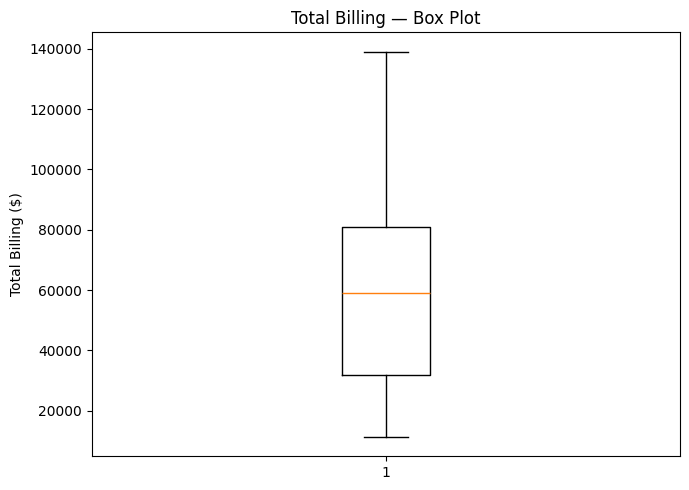

In [18]:
# Start a figure for a single-variable outlier visualization.
plt.figure(figsize=(7, 5))

# A box plot displays the quartiles, median, whiskers, and possible outliers.
plt.boxplot(df_healthcare['Total_Billing'], vert=True)

# Add a title to explain the measurement on display.
plt.title('Total Billing — Box Plot')

# Label the vertical scale in dollars.
plt.ylabel('Total Billing ($)')

# Fit the labels inside the image.
plt.tight_layout()

# Display the box plot.
plt.show()

In [19]:
# Find Q1, the 25th percentile of reported billing.
healthcare_q1 = df_healthcare['Total_Billing'].quantile(0.25)

# Find Q3, the 75th percentile of reported billing.
healthcare_q3 = df_healthcare['Total_Billing'].quantile(0.75)

# Calculate the interquartile range (spread of the middle 50%).
healthcare_iqr = healthcare_q3 - healthcare_q1

# Define the standard Tukey lower outlier cutoff.
healthcare_lower = healthcare_q1 - 1.5 * healthcare_iqr

# Define the standard Tukey upper outlier cutoff.
healthcare_upper = healthcare_q3 + 1.5 * healthcare_iqr

# Keep records below the lower limit or above the upper limit.
healthcare_outliers = df_healthcare.loc[
    (df_healthcare['Total_Billing'] < healthcare_lower) |
    (df_healthcare['Total_Billing'] > healthcare_upper)
]

# Display the computed bounds and how many possible outliers were detected.
print('Lower IQR bound:', healthcare_lower)
print('Upper IQR bound:', healthcare_upper)
print('Potential billing outliers:', len(healthcare_outliers))

# Show any flagged records so you can interpret them in context.
display(healthcare_outliers)

Lower IQR bound: -41735.125
Upper IQR bound: 154672.875
Potential billing outliers: 0


,Department,Facility,Physician_ID,Patient_Admissions,Average_Cost_per_Patient,Total_Billing


## Healthcare · Question 5 (25 points) — Executive Summary

**Required deliverable:** Write **one paragraph containing 5–7 sentences**, addressing **all four** healthcare questions from the PDF:

1. Which medical **Department** generated the highest total billing for the period?
2. Which **Facility** (Location) showed the highest patient volume based on admissions?
3. What insights can you draw from the distribution of **Average Cost per Patient** (tightly clustered or widely varied)?
4. Identify any outliers in **Total Billing**. If there are outliers, what *might* they represent in a healthcare context (such as high-acuity cases)?

**Write your own executive summary in the space below.** Use your outputs from Questions 1–4 and the supporting analyses; do not just paste numerical tables.

> **YOUR RESPONSE (replace with your own 5–7 sentence paragraph):**
>
> [Write here.]

---
# TRACK B — Business Majors + Public Administration Majors

**This is the complete Business/Public Administration question set from the PDF.** Students in this track should complete **Questions 1–5**, following the eight detailed Python tasks where they provide additional instructions.

| Graded question | Points | Where to complete it |
|---|---:|---|
| **Question 1: Descriptive Statistic Summary** | **25** | Tasks 1–3: load, inspect, count/mean/median/mode/standard deviation/min/max |
| **Question 2: Product Analysis** | **25** | Task 4: total revenue by product bar chart |
| **Question 3: Regional Comparison** | **15** | Task 5: total revenue by region bar chart |
| **Question 4: Unit Price Distribution** | **10** | Task 6: histogram with mean and median lines |
| **Question 5: Analysis Questions** | **25** | Task 7 (outlier evidence) and Task 8 (five written prompts) |
| **TOTAL** | **100** | Complete all five questions |

**Assignment dataset:** `sales_assignment_dataset.csv`

| Column | Description |
|---|---|
| `Product` | Product type/name |
| `Region` | Sales region |
| `Salesperson` | Name of sales representative |
| `Units Sold` | Number of units sold |
| `Unit Price` | Price per unit ($) |
| `Total Revenue` | Reported revenue ($), normally units × unit price |

**Submission:** Retain the outputs and graphs in your notebook. Where Blackboard requests a screenshot, take one of the matching output. Write your own responses; no interpretations are supplied.


## Business/Public Administration · Question 1 (25 points) — Descriptive Statistic Summary
### Task 1 of 3 — Load the dataset

**What to do:** Import `sales_assignment_dataset.csv` into a Pandas DataFrame.

**Deliverable:** Executed code showing that the dataset loaded successfully.

**Important:** Question 1 continues in Tasks 2 and 3 below. Complete all three tasks to satisfy this 25-point question.


In [20]:
# Load the sales dataset directly from the raw-content GitHub URL.
# This source belongs to Business and Public Administration majors.
try:
    df_sales = pd.read_csv(sales_url)
except Exception as error:
    # Explain common causes such as internet access or a changed GitHub filename.
    raise RuntimeError(
        'Cannot load sales CSV from GitHub. Confirm an internet connection, '
        'the repository is public, and the sales filename/path are unchanged. '
        f'URL: {sales_url}'
    ) from error

# Print dimensions to confirm a DataFrame was created from the remote CSV.
# Students will calculate and interpret the actual statistics later.
print('Sales dataset loaded from GitHub. Rows and columns:', df_sales.shape)

Sales dataset loaded from GitHub. Rows and columns: (1000, 6)


### Question 1 · Task 2 of 3 — Display the data structure

**What to do:** Display the first **10 rows** and inspect the data types and missing values.

**Deliverable:** First-ten-row output and data-information output, plus screenshots if requested in Blackboard.


In [21]:
# Display the first ten records to see names, values, and layout.
display(df_sales.head(10))

,Product,Region,Salesperson,Units Sold,Unit Price,Total Revenue
0,Pro Laptop,West,Johnson,3,1078.56,3235.68
1,Ultra Widget,East,Johnson,11,76.25,838.75
2,Basic Cable,North,Miller,158,5.01,791.58
3,Ultra Widget,East,Miller,26,37.93,986.18
4,Basic Cable,West,Jones,62,10.18,631.16
5,Ultra Widget,East,Jones,13,73.27,952.51
6,Basic Cable,North,Brown,95,13.97,1327.15
7,Pro Laptop,North,Smith,1,885.64,885.64
8,Smart Fan,South,Miller,28,148.00,4144.00
9,Basic Cable,East,Johnson,81,9.67,783.27


In [22]:
# Inspect variable types and non-null counts to assess data completeness.
df_sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Product        1000 non-null   object 
 1   Region         1000 non-null   object 
 2   Salesperson    1000 non-null   object 
 3   Units Sold     1000 non-null   int64  
 4   Unit Price     1000 non-null   float64
 5   Total Revenue  1000 non-null   float64
dtypes: float64(2), int64(1), object(3)
memory usage: 47.0+ KB


### Question 1 · Task 3 of 3 — Descriptive statistics

**What to do:** Select **Units Sold (volume), Unit Price (unit cost), and Total Revenue (revenue)**. For **each** of these three variables, calculate:

1. Count
2. Mean
3. Median
4. Mode
5. Standard deviation
6. Minimum
7. Maximum

**Deliverable:** A descriptive-statistics summary containing all seven statistics for each of the three named variables. Run every following code cell in this section. Write any requested interpretation yourself.

**Mode display note:** The mode code below prints each variable separately, including its frequency. If every value is unique, it reports **no distinctive mode**. This avoids the misleading `NaN` padding in a combined `.mode()` table.

In [23]:
# List the three numeric sales measurements specified in the PDF.
sales_columns = ['Units Sold', 'Unit Price', 'Total Revenue']

# Select the required data without changing original values.
sales_numeric = df_sales[sales_columns].copy()

# Display the selected variables.
display(sales_numeric.head(10))

,Units Sold,Unit Price,Total Revenue
0,3,1078.56,3235.68
1,11,76.25,838.75
2,158,5.01,791.58
3,26,37.93,986.18
4,62,10.18,631.16
5,13,73.27,952.51
6,95,13.97,1327.15
7,1,885.64,885.64
8,28,148.00,4144.00
9,81,9.67,783.27


In [24]:
# Calculate count, mean, sample standard deviation, minimum, and maximum.
# describe() also supplies quartiles useful for understanding variability.
display(sales_numeric.describe())

,Units Sold,Unit Price,Total Revenue
count,1000.000000,1000.000000,1000.000000
mean,49.985000,242.831900,2558.242450
std,93.608436,368.825996,2628.345665
min,1.000000,5.010000,292.800000
25%,14.000000,30.217500,1137.627500
50%,31.500000,82.770000,1990.420000
75%,48.000000,137.622500,3326.477500
max,1980.000000,1198.300000,37956.800000


In [25]:
# Find the midpoint of each sorted numerical variable.
sales_medians = sales_numeric.median()

# Show each variable's median.
display(sales_medians.to_frame(name='Median'))

,Median
Units Sold,31.50
Unit Price,82.77
Total Revenue,1990.42


In [26]:
# Convert mode results into a clear, compact summary string for one column.
def describe_modes(series):
    # Count the frequency of each nonmissing value.
    counts = series.value_counts(dropna=True)

    # An empty column has no observations from which to calculate a mode.
    if counts.empty:
        return 'No observations'

    # When every value occurs once, none stands out as most frequent.
    if counts.max() == 1:
        return 'No distinctive mode (all values occur once)'

    # Keep all tied most-frequent values and report how often each occurs.
    modes = series.mode(dropna=True)
    return ', '.join(str(value) for value in modes.tolist()) + f' (frequency: {counts.max()})'

# Loop through each numeric variable separately to avoid joining lists of different lengths.
for column in sales_columns:
    # Select one variable (one Pandas Series) by its exact column name.
    values = sales_numeric[column]

    # Count occurrences of each distinct nonmissing value.
    frequency_counts = values.value_counts(dropna=True)

    # Report missing data separately; these are actual missing values, if any.
    missing_count = values.isna().sum()

    # Print a heading to keep each variable's results separate.
    print(f"\nVariable: {column}")
    print(f"Missing observations in source column: {missing_count}")

    # Check that the variable contains at least one nonmissing observation.
    if frequency_counts.empty:
        print("Mode: Cannot determine (no nonmissing observations).")
        continue

    # Find the greatest observed frequency (number of appearances).
    highest_frequency = frequency_counts.max()

    # Calculate all tied modes using the Pandas method required for this lesson.
    tied_modes = values.mode(dropna=True)

    # Explain when there is no informative most-frequent value.
    if highest_frequency == 1:
        print("Mode: No distinctive mode; every observed value occurs once.")
        print("Highest frequency: 1")
    else:
        # Report modes separately rather than a NaN-padded multi-column table.
        print(f"Mode(s): {tied_modes.tolist()}")
        print(f"Frequency of each mode: {highest_frequency}")


Variable: Units Sold
Missing observations in source column: 0
Mode(s): [1, 3]
Frequency of each mode: 41

Variable: Unit Price
Missing observations in source column: 0
Mode(s): [5.43, 5.54, 5.74, 6.12, 7.05, 7.06, 7.98, 10.13, 10.32, 10.78, 10.85, 11.1, 11.43, 11.44, 11.53, 12.2, 13.46, 13.97, 14.26, 22.81, 39.7, 43.66, 43.78, 51.69, 66.22, 76.25, 126.01, 127.28, 129.97, 134.04, 142.24, 1155.17]
Frequency of each mode: 2

Variable: Total Revenue
Missing observations in source column: 0
Mode(s): [983.5, 2041.9, 2440.8]
Frequency of each mode: 2


In [27]:
# Create an empty summary indexed by the three assignment variables.
sales_summary = pd.DataFrame(index=sales_columns)

# Count available observations in each numeric variable.
sales_summary['Count'] = sales_numeric.count()

# Calculate arithmetic averages for units, prices, and revenue.
sales_summary['Mean'] = sales_numeric.mean()

# Calculate the median for each measure.
sales_summary['Median'] = sales_numeric.median()

# Show tied modes and frequencies compactly; avoid long all-unique lists.
sales_summary['Mode(s)'] = sales_numeric.apply(describe_modes)

# Calculate sample standard deviations (n - 1 denominator).
sales_summary['Std. Deviation'] = sales_numeric.std()

# Record each variable's smallest observed value.
sales_summary['Minimum'] = sales_numeric.min()

# Record each variable's largest observed value.
sales_summary['Maximum'] = sales_numeric.max()

# Display the complete seven-measure table.
display(sales_summary)

,Count,Mean,Median,Mode(s),Std. Deviation,Minimum,Maximum
Units Sold,1000,49.98500,31.50,"1, 3 (frequency: 41)",93.608436,1.00,1980.0
Unit Price,1000,242.83190,82.77,"5.43, 5.54, 5.74, 6.12, 7.05, 7.06, 7.98, 10.1...",368.825996,5.01,1198.3
Total Revenue,1000,2558.24245,1990.42,"983.5, 2041.9, 2440.8 (frequency: 2)",2628.345665,292.80,37956.8


**Your response:** > **YOUR RESPONSE:** Describe the most important patterns in the statistics in your own words.

## Business/Public Administration · Question 2 (25 points) — Task 4 — Revenue by Product
**What to do:** Make a bar chart showing total revenue for each product. **Deliverable:** Clearly labeled chart.

In [28]:
# Group transactions according to product name.
# Sum reported Total Revenue within each product group.
sales_revenue_by_product = (
    df_sales.groupby('Product')['Total Revenue']
    .sum()
    .sort_values(ascending=False)
)

# Display totals so students can verify the plotted values.
display(sales_revenue_by_product.to_frame(name='Total Revenue ($)'))

,Total Revenue ($)
Product,
Pro Laptop,613720.51
Smart Fan,572788.82
Eco Bulb,552803.11
Ultra Widget,520746.95
Basic Cable,298183.06


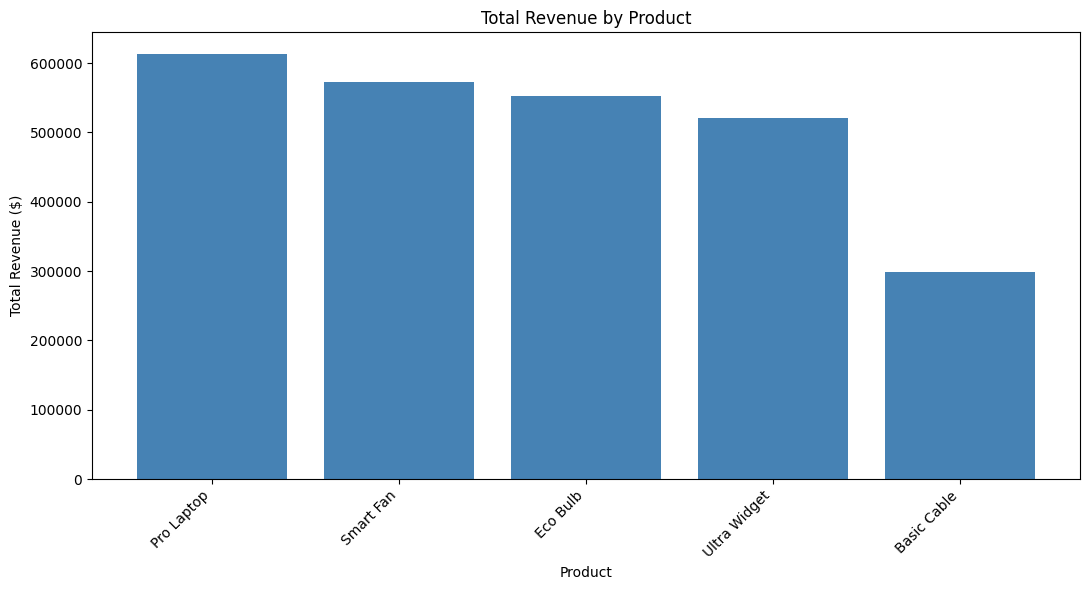

In [29]:
# Set up a figure large enough for product names.
plt.figure(figsize=(11, 6))

# Draw one bar for each product's total revenue.
plt.bar(sales_revenue_by_product.index, sales_revenue_by_product.values, color='steelblue')

# Name the horizontal grouping variable.
plt.xlabel('Product')

# State what monetary values the vertical scale represents.
plt.ylabel('Total Revenue ($)')

# Describe the graphic in the title.
plt.title('Total Revenue by Product')

# Keep long product labels legible.
plt.xticks(rotation=45, ha='right')

# Adjust spacing to avoid cropping.
plt.tight_layout()

# Draw the chart.
plt.show()

**Your response:** > **YOUR RESPONSE:** Interpret the product comparison using your own evidence.

## Business/Public Administration · Question 3 (15 points) — Task 5 — Revenue by Region
**What to do:** Make a bar chart comparing total revenue for each region. **Deliverable:** Labeled chart.

In [30]:
# Group sales by the Region field, then add up revenue in each group.
sales_revenue_by_region = (
    df_sales.groupby('Region')['Total Revenue']
    .sum()
    .sort_values(ascending=False)
)

# Display the totals for verification.
display(sales_revenue_by_region.to_frame(name='Total Revenue ($)'))

,Total Revenue ($)
Region,
East,649010.40
South,641292.63
North,634744.24
West,633195.18


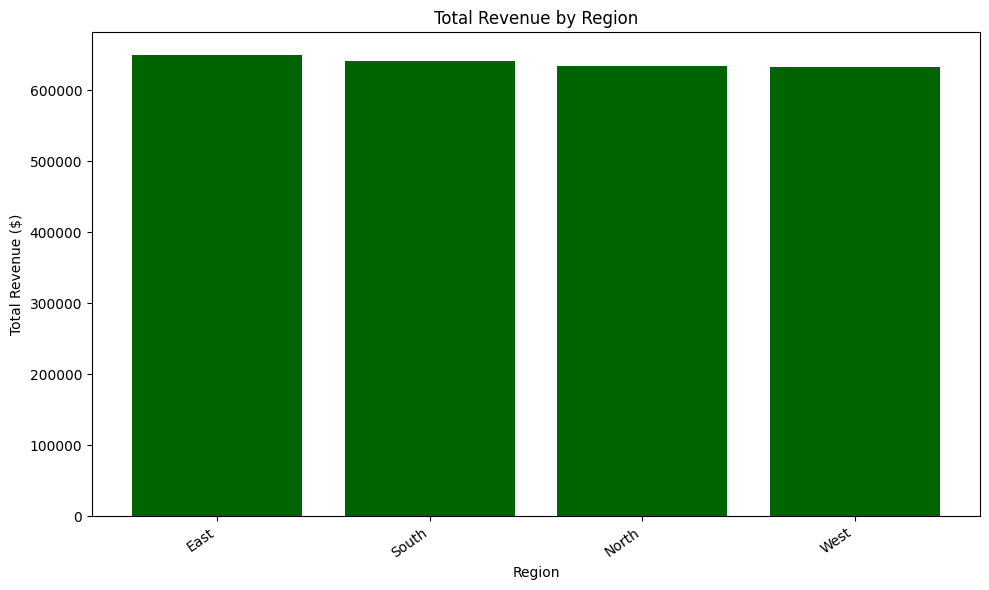

In [31]:
# Create a chart container.
plt.figure(figsize=(10, 6))

# Draw bars representing each region's summed revenue.
plt.bar(sales_revenue_by_region.index, sales_revenue_by_region.values, color='darkgreen')

# Label the horizontal axis with region names.
plt.xlabel('Region')

# Explain the units measured vertically.
plt.ylabel('Total Revenue ($)')

# Add a descriptive title.
plt.title('Total Revenue by Region')

# Rotate region labels in case they are lengthy.
plt.xticks(rotation=35, ha='right')

# Make room for labels.
plt.tight_layout()

# Show the chart.
plt.show()

**Your response:** > **YOUR RESPONSE:** Interpret the geographic pattern yourself.

## Business/Public Administration · Question 4 (10 points) — Task 6 — Unit Price Distribution
**What to do:** Create a **histogram** showing unit prices with **mean and median lines**. **Deliverable:** Labeled histogram.

In [32]:
# Calculate the average price across transactions.
sales_price_mean = df_sales['Unit Price'].mean()

# Calculate the middle transaction-level price.
sales_price_median = df_sales['Unit Price'].median()

# Show the reference values used in the graph.
print('Mean unit price:', sales_price_mean)
print('Median unit price:', sales_price_median)

Mean unit price: 242.8319
Median unit price: 82.77000000000001


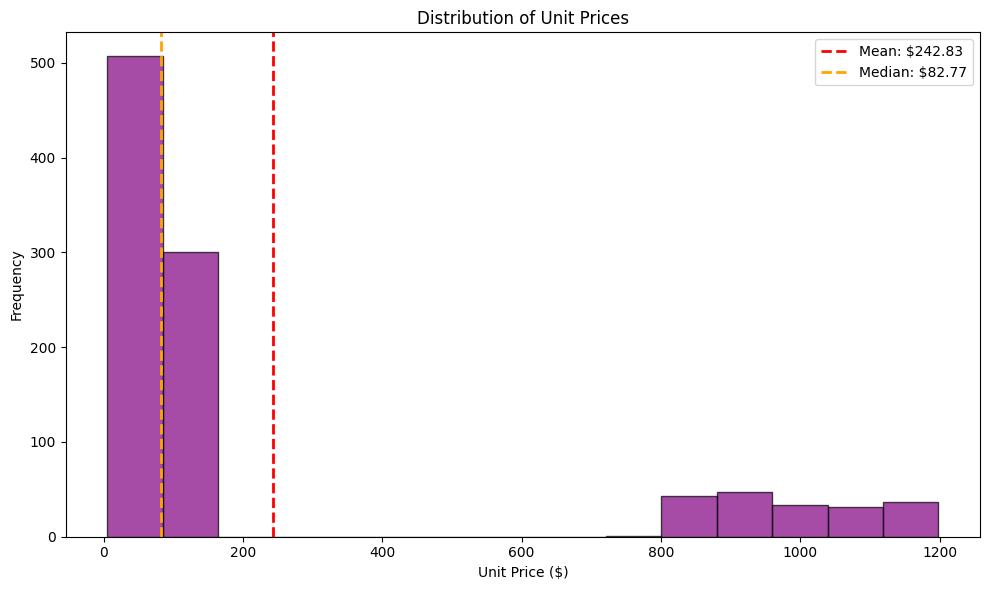

In [33]:
# Start a separate figure for the distribution.
plt.figure(figsize=(10, 6))

# Group transaction unit prices into 15 histogram bins.
plt.hist(df_sales['Unit Price'], bins=15, color='purple', edgecolor='black', alpha=0.7)

# Add a dashed reference line at the mean price.
plt.axvline(sales_price_mean, color='red', linestyle='--', linewidth=2, label=f'Mean: ${sales_price_mean:,.2f}')

# Add another dashed line at the median price.
plt.axvline(sales_price_median, color='orange', linestyle='--', linewidth=2, label=f'Median: ${sales_price_median:,.2f}')

# Label unit price in dollars.
plt.xlabel('Unit Price ($)')

# Explain that the vertical scale is transaction frequency.
plt.ylabel('Frequency')

# Provide a chart heading.
plt.title('Distribution of Unit Prices')

# Draw the line legend for mean and median.
plt.legend()

# Prevent clipping before rendering the chart.
plt.tight_layout()

# Show the histogram.
plt.show()

**Your response:** > **YOUR RESPONSE:** Explain how prices are distributed and what the mean and median suggest.

## Business/Public Administration · Question 5 supporting work — Task 7: Outlier Detection
**What to do:** Identify outliers in **Units Sold** and **Total Revenue** using box plots and the 1.5×IQR method. **Deliverable:** Box plots and outlier count output. This task supports the Question 5 summary.

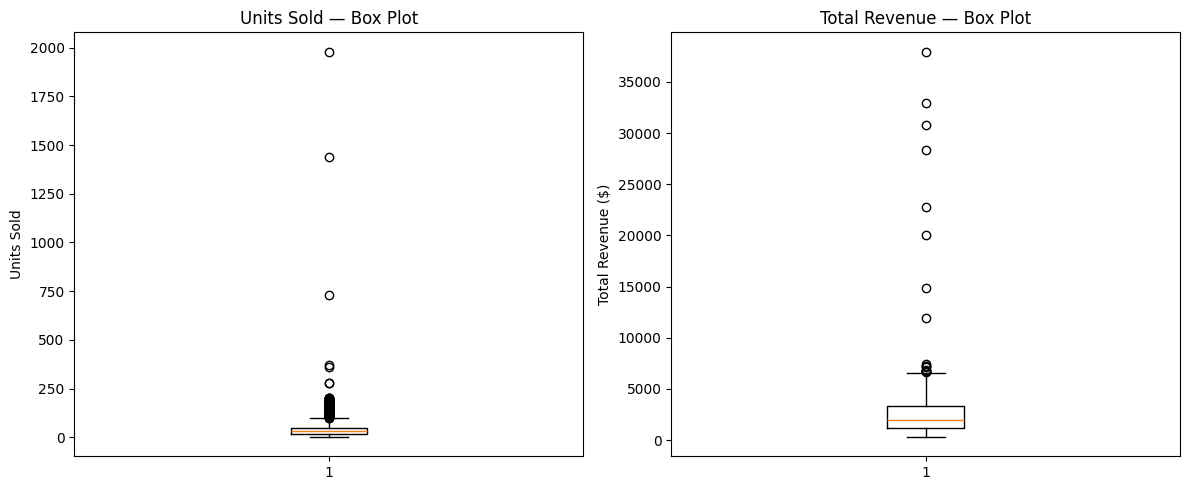

In [34]:
# Create two side-by-side chart areas for the two required variables.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Draw a box plot of unit quantities in the left chart area.
axes[0].boxplot(df_sales['Units Sold'])

# Set its title and vertical measurement label.
axes[0].set_title('Units Sold — Box Plot')
axes[0].set_ylabel('Units Sold')

# Draw a separate box plot of transaction revenue in the right area.
axes[1].boxplot(df_sales['Total Revenue'])

# Label the revenue plot and its units.
axes[1].set_title('Total Revenue — Box Plot')
axes[1].set_ylabel('Total Revenue ($)')

# Space the two charts so their text does not collide.
plt.tight_layout()

# Render the two box plots.
plt.show()

In [35]:
# Define a reusable outlier function for any numeric DataFrame column.
def detect_sales_outliers(column):
    # Find the 25th percentile of the selected column.
    q1 = df_sales[column].quantile(0.25)
    # Find the 75th percentile of the same column.
    q3 = df_sales[column].quantile(0.75)
    # Measure the spread of the central half of observed values.
    iqr = q3 - q1
    # Define the lower cutoff using 1.5 times the IQR.
    lower_bound = q1 - 1.5 * iqr
    # Define the upper cutoff using 1.5 times the IQR.
    upper_bound = q3 + 1.5 * iqr
    # Select rows with a value outside either cutoff.
    flagged_rows = df_sales[(df_sales[column] < lower_bound) | (df_sales[column] > upper_bound)]
    # Return the flagged rows and numeric limits for review.
    return flagged_rows, lower_bound, upper_bound

# Check unit-count outliers using the function above.
sales_units_outliers, sales_units_low, sales_units_high = detect_sales_outliers('Units Sold')

# Check revenue outliers separately using the same method.
sales_revenue_outliers, sales_revenue_low, sales_revenue_high = detect_sales_outliers('Total Revenue')

# Report counts and boundaries, as required by the PDF.
print('Units Sold outlier count:', len(sales_units_outliers))
print('Units Sold lower / upper bounds:', sales_units_low, sales_units_high)
print('Total Revenue outlier count:', len(sales_revenue_outliers))
print('Total Revenue lower / upper bounds:', sales_revenue_low, sales_revenue_high)

Units Sold outlier count: 146
Units Sold lower / upper bounds: -37.0 99.0
Total Revenue outlier count: 18
Total Revenue lower / upper bounds: -2145.6474999999996 6609.7525


**Your response:** > **YOUR RESPONSE:** Explain whether flagged values are plausible business events or need further investigation. Do not automatically delete them.

## Business/Public Administration · Question 5 (25 points) — Task 8: Executive Summary

**What to do:** Write **one paragraph of 5–7 sentences** that answers **all five** questions from the assignment PDF.

1. **Which product generated the highest total revenue?**
2. **Which region had the highest sales performance?**
3. **What insights did you draw from the distribution of unit prices?**
4. **Were there any outliers, and what do they indicate?**
5. **What is ONE actionable recommendation for management based on your analysis?**

Use the evidence you generated in **Questions 1–4** and the outlier work in **Task 7**. Do not copy another student's response.

> **YOUR RESPONSE — replace this placeholder with your own 5–7 sentence paragraph:**
>
> [Write here.]


---
# Submission Checklist

- [ ] I completed **only the track matching my major**.
- [ ] I ran every code cell required for that track, and no traceback is present.
- [ ] All seven descriptive statistics are available for each required variable.
- [ ] My charts have informative titles and axis labels.
- [ ] I inspected mean and median lines on the cost/price histogram.
- [ ] I used the outlier results to support my own interpretation.
- [ ] My executive summary is my own **5–7 sentence paragraph**, addressing each assigned question.
- [ ] I retained notebook outputs and included screenshots if Blackboard specifically requires them.
- [ ] I downloaded my completed `.ipynb` for submission.

**Source:** *Week 5 Assignment – Descriptive Analytics.pdf*, including both major-specific question sets and the expanded Python tasks. The PDF repeats its assignment material; this workbook presents each unique task once, with all original required deliverables.